# How to Build a Healthcare Data Standardization Pipeline Using OMOP CDM
A local PySpark tutorial using six Synthea CSV files and OHDSI ATHENA vocabularies. Target: selected OMOP CDM v5.4 clinical tables, not a complete CDM database. See [CDM specification](https://ohdsi.github.io/CommonDataModel/cdm54.html) and [ATHENA](https://athena.ohdsi.org/). 

Install `pyspark==3.5.3` and `jupyter` in a Python 3.10–3.11 environment with Java 17. Place source CSVs under `data/synthea/` and extracted ATHENA TSV files under `data/vocabulary/`. Do not publish the vocabulary files or notebook outputs containing restricted terminology. Run from top to bottom. 

If you are running in your local machine, below are instructions to install pyspark and notebook

**python3 -m venv .venv**

**source .venv/bin/activate**

**python -m pip install --upgrade pip**

**python -m pip install notebook pyspark**

**python -m pip install matplotlib pandas**

Launch Jupyter Notebook

**cd healthtech-playground/omop-cdm**

**jupyter notebook**

In [1]:
from pathlib import Path
from pyspark.sql import SparkSession, functions as F, Window
spark = (SparkSession.builder.master("local[*]").appName("SyntheaToOMOP")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.sql.shuffle.partitions", "16").getOrCreate())

spark.sparkContext.setLogLevel("ERROR")

ROOT = Path("data")
source = {t: spark.read.option("header", True).csv(str(ROOT/"synthea"/f"{t}.csv"))
          for t in ["patients", "encounters", "conditions", "medications", "procedures", "observations"]}
for t, df in source.items():
    print(t, df.count(), df.columns)


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/Users/lakshmi/healthtech-playground/.venv/lib/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/26 12:47:00 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


patients 115 ['Id', 'BIRTHDATE', 'DEATHDATE', 'SSN', 'DRIVERS', 'PASSPORT', 'PREFIX', 'FIRST', 'MIDDLE', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'FIPS', 'ZIP', 'LAT', 'LON', 'HEALTHCARE_EXPENSES', 'HEALTHCARE_COVERAGE', 'INCOME']
encounters 5985 ['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PROVIDER', 'PAYER', 'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE', 'REASONDESCRIPTION']
conditions 4070 ['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'SYSTEM', 'CODE', 'DESCRIPTION']
medications 4454 ['START', 'STOP', 'PATIENT', 'PAYER', 'ENCOUNTER', 'CODE', 'DESCRIPTION', 'BASE_COST', 'PAYER_COVERAGE', 'DISPENSES', 'TOTALCOST', 'REASONCODE', 'REASONDESCRIPTION']
procedures 16777 ['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'SYSTEM', 'CODE', 'DESCRIPTION', 'BASE_COST', 'REASONCODE', 'REASONDESCRIPTION']
observations 75004 ['DATE', 'PATIENT', 'ENCOUNTER

## Vocabulary mapping
A source code is meaningful only together with its vocabulary. Look up the source concept, then follow valid `Maps to` relationships to active standard concepts. Standard source concepts can map to themselves. Keep one-to-many mappings; use 0 for unmapped concepts. The vocabulary release should be recorded for reproducibility. This example uses active mappings in the downloaded release, not historical as-of-event mappings.

In [2]:
def vocab(name):
    return spark.read.option("header", True).option("sep", "\t").csv(str(ROOT/"vocabulary"/f"{name}.csv"))
concept = vocab("CONCEPT").withColumn("concept_id", F.col("concept_id").cast("int"))
rel = vocab("CONCEPT_RELATIONSHIP")
active = concept.filter(F.col("invalid_reason").isNull() | (F.col("invalid_reason") == ""))
standard = active.filter(F.col("standard_concept") == "S")
links = (rel.filter((F.col("relationship_id") == "Maps to") & (F.col("invalid_reason").isNull() | (F.col("invalid_reason") == "")))
         .select(F.col("concept_id_1").cast("int").alias("src"), F.col("concept_id_2").cast("int").alias("dst")))
links = links.union(standard.select(F.col("concept_id").alias("src"), F.col("concept_id").alias("dst"))).distinct()
lookup = (active.alias("s").join(links, F.col("s.concept_id") == F.col("src"), "left")
          .join(standard.alias("t"), F.col("dst") == F.col("t.concept_id"), "left")
          .select(F.col("s.vocabulary_id").alias("vocab"), F.col("s.concept_code").alias("code"),
                  F.col("s.concept_id").alias("source_concept_id"), F.col("t.concept_id").alias("standard_id"),
                  F.col("t.domain_id").alias("domain")).distinct())
def map_codes(df):
    return (df.join(lookup, ["vocab", "code"], "left")
            .fillna(0, subset=["source_concept_id", "standard_id"]))
def check_concept(cid, domain):
    assert standard.filter((F.col("concept_id") == cid) & (F.col("domain_id") == domain)).count() == 1, (cid, domain)
concept.filter((F.col("vocabulary_id") == "SNOMED") & (F.col("concept_code") == "44054006")).show(truncate=False)


+----------+------------------------+---------+-------------+----------------+----------------+------------+----------------+--------------+--------------+
|concept_id|concept_name            |domain_id|vocabulary_id|concept_class_id|standard_concept|concept_code|valid_start_date|valid_end_date|invalid_reason|
+----------+------------------------+---------+-------------+----------------+----------------+------------+----------------+--------------+--------------+
|201826    |Type 2 diabetes mellitus|Condition|SNOMED       |Disorder        |S               |44054006    |20020131        |20991231      |NULL          |
+----------+------------------------+---------+-------------+----------------+----------------+------------+----------------+--------------+--------------+



## PERSON and VISIT_OCCURRENCE
Create integer crosswalks from source UUIDs. Sorted row numbers are reproducible for a fixed full snapshot, not stable across changing input datasets. Demographic and visit mappings below are explicit tutorial crosswalks, unknown values use 0. 

Validate chosen IDs against your vocabulary. Do not infer race or ethnicity from names.

In [3]:
def ids(df, source_col, target_col):
    return df.select(F.col(source_col).alias(source_col)).distinct().filter(F.col(source_col).isNotNull()).withColumn(target_col, F.row_number().over(Window.orderBy(source_col)))
def dictionary(col, pairs):
    args = [F.lit(x) for pair in pairs.items() for x in pair]
    return F.coalesce(F.element_at(F.create_map(*args), F.lower(F.trim(F.col(col)))), F.lit(0))
def date(col):
    return F.to_date(F.substring(F.col(col), 1, 10), "yyyy-MM-dd")
for cid, dom in [(8507,"Gender"),(8532,"Gender"),(38003563,"Ethnicity"),(38003564,"Ethnicity"),(8527,"Race"),(8516,"Race"),(8515,"Race"),(8657,"Race"),(8557,"Race"),(9201,"Visit"),(9202,"Visit"),(9203,"Visit"),(32817,"Type Concept"),(32880,"Type Concept")]:
    check_concept(cid, dom)
pid = ids(source["patients"], "Id", "person_id")
vid = ids(source["encounters"], "Id", "visit_occurrence_id")
person = (source["patients"].join(pid,"Id").withColumn("birth",date("BIRTHDATE"))
    .select("person_id", dictionary("GENDER", {"m":8507,"f":8532}).alias("gender_concept_id"),
            F.year("birth").alias("year_of_birth"), F.month("birth").alias("month_of_birth"), F.dayofmonth("birth").alias("day_of_birth"),
            dictionary("RACE", {"white":8527,"black":8516,"asian":8515,"native":8657,"hawaiian":8557}).alias("race_concept_id"),
            dictionary("ETHNICITY", {"hispanic":38003563,"nonhispanic":38003564}).alias("ethnicity_concept_id"),
            F.col("Id").alias("person_source_value"), F.col("GENDER").alias("gender_source_value"), F.col("RACE").alias("race_source_value"), F.col("ETHNICITY").alias("ethnicity_source_value")))
person.show(5)
visits = source["encounters"].join(vid,"Id").join(pid.withColumnRenamed("Id","PATIENT"),"PATIENT")
visit_occurrence = visits.select("visit_occurrence_id","person_id", dictionary("ENCOUNTERCLASS", {"inpatient":9201,"outpatient":9202,"ambulatory":9202,"wellness":9202,"emergency":9203,"urgentcare":9202}).alias("visit_concept_id"), date("START").alias("visit_start_date"),date("STOP").alias("visit_end_date"),F.lit(32817).alias("visit_type_concept_id"),F.col("ENCOUNTERCLASS").alias("visit_source_value"))
visit_occurrence.show(5)


+---------+-----------------+-------------+--------------+------------+---------------+--------------------+--------------------+-------------------+-----------------+----------------------+
|person_id|gender_concept_id|year_of_birth|month_of_birth|day_of_birth|race_concept_id|ethnicity_concept_id| person_source_value|gender_source_value|race_source_value|ethnicity_source_value|
+---------+-----------------+-------------+--------------+------------+---------------+--------------------+--------------------+-------------------+-----------------+----------------------+
|        1|             8507|         1973|             3|          12|           8557|            38003564|006232dd-9560-5c9...|                  M|         hawaiian|           nonhispanic|
|        2|             8507|         2023|            11|           1|           8527|            38003564|007b80d2-abda-8c6...|                  M|            white|           nonhispanic|
|        3|             8507|         2018|  

## Clinical events
Normalize the four source event tables to a shared shape, join patient and visit crosswalks, map clinical codes, and route by target domain. Unmapped or out-of-scope records are retained in a review DataFrame. This tutorial does not implement `Maps to value`, device routing, dosage, or categorical clinical value mappings. Drug end dates fall back to start date when absent (documented assumption, not actual duration).

In [4]:
from functools import reduce
# Synthea CSV releases may omit SYSTEM; defaults below reflect usual export conventions.
def normalize(name, default_vocab, start, stop=None):
    df = source[name]
    sys = F.lower(F.trim(F.col("SYSTEM"))) if "SYSTEM" in df.columns else F.lit(None).cast("string")
    v = (F.when(sys.isin("snomed-ct","snomed","http://snomed.info/sct"), "SNOMED")
         .when(sys.isin("loinc","http://loinc.org"), "LOINC")
         .when(sys.isin("rxnorm","http://www.nlm.nih.gov/research/umls/rxnorm"), "RxNorm")
         .when(sys.isNull() | (sys == ""), default_vocab).otherwise(sys))
    def optional(key): return F.col(key) if key in df.columns else F.lit(None).cast("string")
    return df.select(F.lit(name).alias("source_table"),"PATIENT","ENCOUNTER",v.alias("vocab"), F.col("CODE").alias("code"),date(start).alias("start_date"), date(stop).alias("end_date") if stop and stop in df.columns else F.lit(None).cast("date").alias("end_date"),optional("VALUE").alias("raw_value"),optional("UNITS").alias("raw_unit"))
events = reduce(lambda a,b:a.unionByName(b), [normalize("conditions","SNOMED","START","STOP"),normalize("procedures","SNOMED","START","STOP") if "START" in source["procedures"].columns else normalize("procedures","SNOMED","DATE"),normalize("medications","RxNorm","START","STOP"),normalize("observations","LOINC","DATE")])
events = events.withColumn("event_id",F.monotonically_increasing_id()).cache()
event_count = events.count()
visit_keys = visits.select(F.col("Id").alias("ENCOUNTER"),"PATIENT","visit_occurrence_id")
mapped = map_codes(events.join(pid.withColumnRenamed("Id","PATIENT"),"PATIENT","left").join(visit_keys,["PATIENT","ENCOUNTER"],"left")).cache()
mapped.groupBy("source_table","domain").count().show(100,False)
allowed = ["Condition","Drug","Procedure","Measurement","Observation"]
valid = (F.col("person_id").isNotNull() & F.col("start_date").isNotNull() & (F.col("standard_id") != 0) & F.coalesce(F.col("domain").isin(allowed),F.lit(False)) & (F.col("ENCOUNTER").isNull() | F.col("visit_occurrence_id").isNotNull()))
review = mapped.filter(~valid)
ready = mapped.filter(valid).cache()
review.groupBy("source_table","domain").count().show(100,False)


[Stage 139:===>                                                   (1 + 14) / 16]

+------------+-----------+-----+
|source_table|domain     |count|
+------------+-----------+-----+
|conditions  |Observation|2081 |
|observations|NULL       |4282 |
|observations|Observation|27425|
|observations|Measurement|43294|
|observations|Procedure  |2    |
|procedures  |Procedure  |9012 |
|medications |Drug       |4455 |
|conditions  |Condition  |1967 |
|procedures  |Measurement|3629 |
|procedures  |NULL       |481  |
|procedures  |Observation|3645 |
|procedures  |Condition  |1    |
|conditions  |NULL       |22   |
|observations|Note       |1    |
|procedures  |Drug       |1    |
|procedures  |Device     |8    |
+------------+-----------+-----+

+------------+------+-----+
|source_table|domain|count|
+------------+------+-----+
|observations|NULL  |4282 |
|procedures  |NULL  |481  |
|conditions  |NULL  |22   |
|observations|Note  |1    |
|procedures  |Device|8    |
+------------+------+-----+



In [5]:
# Unit mapping: exact UCUM code lookup. No unit conversion is performed.
units = standard.filter((F.col("vocabulary_id") == "UCUM") & (F.col("domain_id") == "Unit")).groupBy("concept_code").agg(F.min("concept_id").alias("unit_concept_id"))
ready = (ready.join(units,ready.raw_unit == units.concept_code,"left").drop("concept_code").withColumn("unit_concept_id",F.when(F.col("raw_unit").isNotNull(), F.coalesce(F.col("unit_concept_id"),F.lit(0))))
         .withColumn("numeric_value", F.expr("try_cast(raw_value as double)")))
def domain_rows(domain, prefix):
    return ready.filter(F.col("domain") == domain).withColumn(prefix+"_id", F.row_number().over(Window.orderBy("event_id","standard_id","source_concept_id")))
def common(prefix):
    return [prefix+"_id","person_id", F.col("standard_id").alias(prefix.replace("_occurrence", "").replace("_exposure", "")+"_concept_id"),"visit_occurrence_id"]
def provenance(prefix):
    return [F.lit(32817).alias(prefix+"_type_concept_id"), F.col("code").alias(prefix+"_source_value"), F.col("source_concept_id").alias(prefix+"_source_concept_id")]
condition_occurrence = domain_rows("Condition","condition_occurrence").select(*common("condition_occurrence"),F.col("start_date").alias("condition_start_date"),F.col("end_date").alias("condition_end_date"),*provenance("condition"))
drug_exposure = domain_rows("Drug","drug_exposure").select(*common("drug_exposure"),F.col("start_date").alias("drug_exposure_start_date"),F.coalesce("end_date","start_date").alias("drug_exposure_end_date"),*provenance("drug"))
procedure_occurrence = domain_rows("Procedure","procedure_occurrence").select(*common("procedure_occurrence"),F.col("start_date").alias("procedure_date"),F.col("end_date").alias("procedure_end_date"),*provenance("procedure"))
measurement = domain_rows("Measurement","measurement").select(*common("measurement"),F.col("start_date").alias("measurement_date"),F.col("numeric_value").alias("value_as_number"),"unit_concept_id", F.col("raw_unit").alias("unit_source_value"),F.col("raw_value").alias("value_source_value"),*provenance("measurement"))
observation = domain_rows("Observation","observation").select(*common("observation"),F.col("start_date").alias("observation_date"),F.col("numeric_value").alias("value_as_number"),F.when(F.col("numeric_value").isNull(),F.substring("raw_value",1,60)).alias("value_as_string"),"unit_concept_id",*provenance("observation"))


## OBSERVATION_PERIOD
For this synthetic dataset only, approximate coverage using first and last recorded visit/event dates. This does not establish continuous enrollment or actual observation coverage in hospital data. Concept 32880 is a period inferred from EHR data, verify the name in your vocabulary.

In [6]:
bounds = visit_occurrence.select("person_id",F.col("visit_start_date").alias("lo"),F.col("visit_end_date").alias("hi")).unionByName(ready.select("person_id",F.col("start_date").alias("lo"),F.coalesce("end_date","start_date").alias("hi")))
observation_period = (bounds.groupBy("person_id").agg(F.min("lo").alias("observation_period_start_date"),F.max(F.greatest("lo","hi")).alias("observation_period_end_date"))
    .withColumn("observation_period_id",F.row_number().over(Window.orderBy("person_id"))).withColumn("period_type_concept_id",F.lit(32880)))
tables = {name: globals()[name] for name in ["person","visit_occurrence","condition_occurrence","drug_exposure","procedure_occurrence","measurement","observation","observation_period"]}


In [7]:
tables = {
    "person": person,
    "visit_occurrence": visit_occurrence,
    "condition_occurrence": condition_occurrence,
    "drug_exposure": drug_exposure,
    "procedure_occurrence": procedure_occurrence,
    "measurement": measurement,
    "observation": observation,
    "observation_period": observation_period
}

for name, df in tables.items():
    print(f"{name}: {df.count():,} records")

person: 115 records
visit_occurrence: 5,985 records
condition_occurrence: 1,968 records
drug_exposure: 4,456 records
procedure_occurrence: 9,014 records
measurement: 46,923 records
observation: 33,151 records
observation_period: 115 records


## Validate and save
These are selected-column educational tables. Optional CDM columns are omitted, a full CDM requires the official DDL, supporting metadata, additional domains and broader quality checks. Reconciliation uses distinct source event IDs because a source code may produce multiple target concepts.

In [8]:
required = {"person":["year_of_birth","gender_concept_id","race_concept_id","ethnicity_concept_id"],"visit_occurrence":["visit_concept_id","visit_start_date","visit_end_date","visit_type_concept_id"],"condition_occurrence":["condition_concept_id","condition_start_date","condition_type_concept_id"],"drug_exposure":["drug_concept_id","drug_exposure_start_date","drug_exposure_end_date","drug_type_concept_id"],"procedure_occurrence":["procedure_concept_id","procedure_date","procedure_type_concept_id"],"measurement":["measurement_concept_id","measurement_date","measurement_type_concept_id"],"observation":["observation_concept_id","observation_date","observation_type_concept_id"],"observation_period":["observation_period_start_date","observation_period_end_date","period_type_concept_id"]}
issues = []
for name, df in tables.items():
    df = df.cache(); tables[name] = df
    key = name + "_id"
    count = df.count()
    missing = df.filter(reduce(lambda a,b:a|b,[F.col(x).isNull() for x in [key,"person_id"]+required[name]])).count()
    duplicates = count - df.select(key).distinct().count()
    orphan = df.join(person.select("person_id"),"person_id","left_anti").count()
    orphan_visit = df.filter(F.col("visit_occurrence_id").isNotNull()).join(visit_occurrence.select("visit_occurrence_id","person_id"),["visit_occurrence_id","person_id"],"left_anti").count() if "visit_occurrence_id" in df.columns and name != "visit_occurrence" else 0
    print(name,count,"missing",missing,"duplicate",duplicates,"orphan person",orphan,"orphan visit",orphan_visit)
    if missing or duplicates or orphan or orphan_visit: issues.append(name)
covered = ready.select("event_id").union(review.select("event_id")).distinct().count()
print("Source events:",event_count,"Accounted for:",covered,"Review rows:",review.count())
assert covered == event_count

person 115 missing 0 duplicate 0 orphan person 0 orphan visit 0
visit_occurrence 5985 missing 0 duplicate 0 orphan person 0 orphan visit 0
condition_occurrence 1968 missing 0 duplicate 0 orphan person 0 orphan visit 0
drug_exposure 4456 missing 0 duplicate 0 orphan person 0 orphan visit 0
procedure_occurrence 9014 missing 0 duplicate 0 orphan person 0 orphan visit 0
measurement 46923 missing 0 duplicate 0 orphan person 0 orphan visit 0
observation 33151 missing 0 duplicate 0 orphan person 0 orphan visit 0
observation_period 115 missing 0 duplicate 0 orphan person 0 orphan visit 0
Source events: 100305 Accounted for: 100305 Review rows: 4794


## Clinical analytics
Count distinct patients by standardized diagnosis concept. Counts reflect mapped records only, not clinical prevalence. Keep vocabulary and generated data local unless redistribution is permitted.

In [9]:
OMOP_DIR = ROOT / "omop"
OMOP_DIR.mkdir(parents=True, exist_ok=True)

for name, df in tables.items():
    output_path = OMOP_DIR / name

    df.write.mode("overwrite").parquet(
        str(output_path)
    )

    print(f"Successfully saved: {output_path}")

review.write.mode("overwrite").parquet(
    str(ROOT / "omop_review")
)

Successfully saved: data/omop/person
Successfully saved: data/omop/visit_occurrence
Successfully saved: data/omop/condition_occurrence
Successfully saved: data/omop/drug_exposure
Successfully saved: data/omop/procedure_occurrence
Successfully saved: data/omop/measurement
Successfully saved: data/omop/observation
Successfully saved: data/omop/observation_period


In [10]:
for name in tables:
    df = spark.read.parquet(
        str(OMOP_DIR / name)
    )

    df.createOrReplaceTempView(name)

concept.createOrReplaceTempView("concept")

In [11]:
spark.sql("SHOW TABLES").show(truncate=False)

+---------+--------------------+-----------+
|namespace|tableName           |isTemporary|
+---------+--------------------+-----------+
|         |concept             |true       |
|         |condition_occurrence|true       |
|         |drug_exposure       |true       |
|         |measurement         |true       |
|         |observation         |true       |
|         |observation_period  |true       |
|         |person              |true       |
|         |procedure_occurrence|true       |
|         |visit_occurrence    |true       |
+---------+--------------------+-----------+



## Register OMOP tables as Spark SQL views

In [12]:
spark.sql("""
    SELECT
        c.concept_id,
        c.concept_name,
        COUNT(DISTINCT o.person_id) AS patients
    FROM condition_occurrence o
    JOIN concept c
        ON o.condition_concept_id = c.concept_id
    GROUP BY
        c.concept_id,
        c.concept_name
    ORDER BY patients DESC
    LIMIT 10
""").show(truncate=False)


[Stage 1007:>                                                     (0 + 14) / 14]

+----------+-----------------------------+--------+
|concept_id|concept_name                 |patients|
+----------+-----------------------------+--------+
|4281516   |Gingivitis                   |95      |
|40481087  |Viral sinusitis              |76      |
|4172829   |Limited social contact       |74      |
|4309238   |Social isolation             |70      |
|4060985   |Body mass index 30+ - obesity|64      |
|4112343   |Acute viral pharyngitis      |56      |
|40274283  |Primary dental caries        |54      |
|4090111   |Gingival disease             |52      |
|37018196  |Prediabetes                  |49      |
|260139    |Acute bronchitis             |43      |
+----------+-----------------------------+--------+



## Clinical Domain Distribution
Clinical vocabulary mapping helps us determine the appropriate
OMOP target table based on the clinical meaning of each record.

The following visualization shows how records from different
Synthea source tables are distributed across OMOP clinical domains.

This demonstrates that healthcare data standardization is not
always a one-to-one table transformation.

In [13]:
domain_distribution = (
    mapped
    .withColumn(
        "domain",
        F.coalesce(F.col("domain"), F.lit("Unmapped"))
    )
    .groupBy("source_table", "domain")
    .count()
    .orderBy("source_table", F.desc("count"))
)

domain_distribution.show(100, truncate=False)

+------------+-----------+-----+
|source_table|domain     |count|
+------------+-----------+-----+
|conditions  |Observation|2081 |
|conditions  |Condition  |1967 |
|conditions  |Unmapped   |22   |
|medications |Drug       |4455 |
|observations|Measurement|43294|
|observations|Observation|27425|
|observations|Unmapped   |4282 |
|observations|Procedure  |2    |
|observations|Note       |1    |
|procedures  |Procedure  |9012 |
|procedures  |Observation|3645 |
|procedures  |Measurement|3629 |
|procedures  |Unmapped   |481  |
|procedures  |Device     |8    |
|procedures  |Condition  |1    |
|procedures  |Drug       |1    |
+------------+-----------+-----+



/Users/lakshmi/healthtech-playground/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/lakshmi/healthtech-playground/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


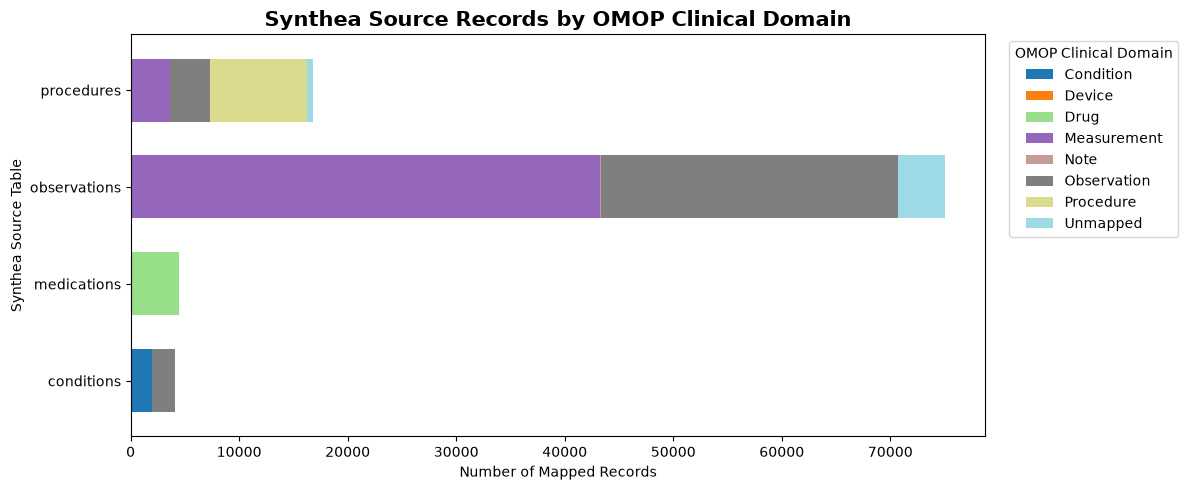

In [14]:
import matplotlib.pyplot as plt

distribution_pd = domain_distribution.toPandas()

pivot_df = distribution_pd.pivot_table(
    index="source_table",
    columns="domain",
    values="count",
    aggfunc="sum",
    fill_value=0
)

ax = pivot_df.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 5),
    colormap="tab20",
    width=0.65
)

ax.set_title(
    "Synthea Source Records by OMOP Clinical Domain",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Number of Mapped Records")
ax.set_ylabel("Synthea Source Table")

ax.legend(
    title="OMOP Clinical Domain",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

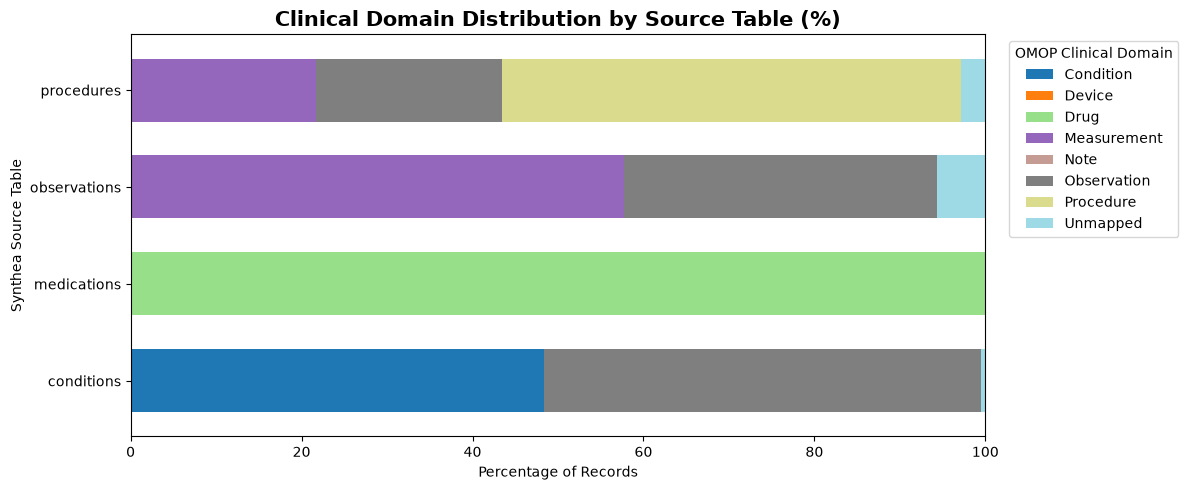

In [15]:
percentage_df = (
    pivot_df.div(pivot_df.sum(axis=1), axis=0) * 100
)

ax = percentage_df.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 5),
    colormap="tab20",
    width=0.65
)

ax.set_title(
    "Clinical Domain Distribution by Source Table (%)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Percentage of Records")
ax.set_ylabel("Synthea Source Table")
ax.set_xlim(0, 100)

ax.legend(
    title="OMOP Clinical Domain",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()